<a href="https://colab.research.google.com/github/LucasAbCV/procesamientoDelHabla/blob/main/Abruzzo_Lucas_PH_TP1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 PROCESAMIENTO DEL HABLA: webscrapping

**Crea una copia de este notebook en tu google colab**

**Renombra el notebook con el siguiente formato APELLIDO_NOMBRE_PH_TP1.ipynb**

**[Escriba aquí su nombre completo.]**


* Resolver las consignas comentando el código fuente, indicando desde dónde fue extraido o generado.

* Explicar y justificar cada paso realizado usando los bloques de texto.

* Publique enlace público a su notebook en google colab y también enlace a su repositorio github de la materia.


## EJERCICIO CONSIGNA

* Cree una nube de palabras de un texto en español.

* Dicho texto puede ser descargado de Internet (webscrapping) o extraído del dataset de alguna librería.

* Puede usar cualquier libreria o herramienta para obtener el texto de su interés.

* En este notebook explica el paso a paso del proceso.



## 1- Webscrapping

Extrae un texto de Internet de una sóla página web usando alguna de las técnicas de webscrapping vistas en clase. Busca el discurso de alguna persona quien te inspire o haya dado una charla motivadora.

No puedes repetir ni usar ni el mismo texto ni la misma web que otra persona quien ya entregó en el foro.

Abajo añade los bloques de código y texto necesarios. Explica paso a paso como descargaste el texto de tu interés.


###1.1 Página para webscrapping
Para el tp, utilice la reflexión de Carl Sagan "Pale Blue Dot" traducida oficialmente al español en la url: https://www.awakin.org/v2/read/view.php?tid=682&lang=Spanish

###1.2 Instalaciones necesarias

In [84]:
#Para solicitudes HTTP, lectura y análisis HTML, parser HTML.
! pip install requests beautifulsoup4 html5lib
#Nubes de palabras.
! pip install wordcloud

#Fuente: documentación/archivos colab de la clase 2 de webscrapping y del ejemplo de esta actividad

###1.3 Librerías

In [85]:
import requests                                     #Solicitudes HTTP.
from bs4 import BeautifulSoup                       #Lectura/análisis HTML.
import nltk                                         #Procesamiento de textos.
from nltk.corpus import stopwords                   #Palabaras frecuentes que no aportan mucho significado.
from nltk.tokenize import word_tokenize             #Tokenizador.
from nltk.stem import SnowballStemmer               #Reductor de palabras a la raiz.
from wordcloud import WordCloud                     #Nube de palabras.
import matplotlib.pyplot as plt                     #Graficar.
import string                                       #Manejo de strings
import re                                           #Manejo expresiones regulares
from nltk.tokenize import sent_tokenize             #Para separar texto en oraciones
import numpy as np                                  #Calculo numerico y arrays


#Fuente: recopilación de librerías utilizadas en la clase 2 de webscrapping (archivo de ejemplo de colab), el notbook de vectorización y el notebook de limpieza de la clase 1

###1.4 Obtención del texto

In [86]:
#URL:
url = "https://www.awakin.org/v2/read/view.php?tid=682&lang=Spanish"

#Solicitud HTTP.
respuesta = requests.get(url) #Se almacena la respuesta del servidor.
respuesta.raise_for_status()  #Excepción si hay un error en la solicitud.

soup = BeautifulSoup(respuesta.text, 'html.parser')       #Se obtiene la respuesta del servidor como texto(HTML), lo analizar con el parser y se almacena como un objeto recorrible.


#Fuente: notebook de la clase 2 sobre webscrapping

In [87]:
#Texto.
soup.get_text()

#Fuente: notebook de la clase 2 sobre webscrapping

'\n\n\n\n\n\n\n\n\n\nPale Blue Dot, by Carl Sagan\n\n\n\n\n\n\n\n\n\n\n\n\n\nAwakin.org\n\n\n\nReadings\nCircles\nCalls\nSubscribe\n\n\n\n\n\n\n\n\n\nAwakin Readings\nPale Blue Dot\n\n\nCarl Sagan\n\n\xa0 3 min read\n·\n\xa0 42 reflections\n\n\n\n\n Listen\n\n\n Spanish                \n\nEnglish\nSpanish\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nEL PUNTO AZUL PÁLIDO\n\r\nObserva de nuevo ese punto. Ahí es donde estamos. Ese es nuestro hogar. Esos somos nosotros. Sobre ese punto se encuentra cada ser que amas, cada ser que conoces, cada ser del que has oído hablar; cada ser humano que alguna vez existió y vivió su vida. Ahí está la suma de nuestro júbilo y nuestro sufrimiento; de miles de sólidas religiones, ideologías y doctrinas económicas; de cada cazador y recolector; de cada héroe y cada cobarde, de cada creador y destructor de civilizaciones, de cada monarca y campesino; de cada joven pareja enamorada; cada madre, padre y prometedor infante; de cada inventor y explorador, de cada predicador

## 2- Preprocesamiento

###2.1 Limpieza

In [88]:
#Busca en el HTML el primer elemento que coincida con el selector CSS (el primer <div> que sea hijo directo de un <div> con las clases aw-reading y perm_post, y que además no tenga la clase d-sm-none).
div = soup.select_one('div.aw-reading.perm_post > div:not(.d-sm-none)')

if div:                                                             #Si tuvo éxito.
    #extrae el texto del div anterior eliminando espacios en blanco innecesarios al principio y al final de cada fragmento de texto. Además separa los fragmentos de texto con salto de línea.
    texto_completo = div.get_text(strip=True, separator="\n")
    print(texto_completo)

#Fuente: se le suministro una captura de pantalla a ChatGpt sobre la estructura del código fuente de la página y se ecsribió en siguiente prompt:
#"dado este código, como puedo acceder u obtener el texto dentro del div seleccionado".
#En la captura figuraba un div con la estructura: "<div> == $0" y que conenía el texto en cuestión

EL PUNTO AZUL PÁLIDO
Observa de nuevo ese punto. Ahí es donde estamos. Ese es nuestro hogar. Esos somos nosotros. Sobre ese punto se encuentra cada ser que amas, cada ser que conoces, cada ser del que has oído hablar; cada ser humano que alguna vez existió y vivió su vida. Ahí está la suma de nuestro júbilo y nuestro sufrimiento; de miles de sólidas religiones, ideologías y doctrinas económicas; de cada cazador y recolector; de cada héroe y cada cobarde, de cada creador y destructor de civilizaciones, de cada monarca y campesino; de cada joven pareja enamorada; cada madre, padre y prometedor infante; de cada inventor y explorador, de cada predicador de buenas costumbres y cada político corrupto; de cada “súper estrella” y “líder supremo”. Cada uno de los santos y pecadores en la historia de nuestra especie habitó aquí, en una mota de polvo suspendida en un rayo de sol.
El planeta Tierra es un minúsculo tablero dentro de un gigantesco escenario cósmico. Piensa en los ríos de sangre que 

###2.2 Stowords

In [89]:
# Descargar recursos necesarios.
# 'punkt' y 'punkt_tab' son necesarios para la tokenización.
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')                   #Descarga de las "palabras vacías".


#Fuente: Notebook de limpieza de textos de la clase 1, y se le paso a ChatGPT: "dado un texto, como puedo separarlo en palabras". Sin embargo
#split requerìa especficar el criterio o caracter de separación. Asi que le pedi "alguna técnica más compleja basada en nuetsro lenguaje o reglas de gramáticas mas implícitas"
#En base a esto, me ofreció la tokenización y las descargas necesarias

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [90]:
tokens = word_tokenize(texto_completo.lower(), language='spanish')    #Toma el texto, lo pasa a minúsculas y lo convierte en una lista de tokens (palabras) según las reglas del español.

#Fuente: prompt de la celda anterior

In [91]:
lista_stop_words = set(stopwords.words('spanish'))     #Lista de palabras frecuentes del español que son vacías, no aportan significado.

#Fuente: Notebook de limpieza de textos de la clase 1

### 2.3 Muestra las stop words que tenga tu texto.

In [92]:
my_stop_words = [word for word in tokens if word in lista_stop_words]     #Crea una lista de palabras del texto tokenizado si esas palabras se encuentran en la lista de stopwords
print(my_stop_words)

#Fuente: adptación lógica del código del notbook de la clase 1 sobre limpieza de textos

['el', 'de', 'ese', 'es', 'donde', 'estamos', 'ese', 'es', 'nuestro', 'esos', 'somos', 'nosotros', 'sobre', 'ese', 'se', 'que', 'que', 'del', 'que', 'has', 'que', 'y', 'su', 'está', 'la', 'de', 'nuestro', 'y', 'nuestro', 'de', 'de', 'y', 'de', 'y', 'de', 'y', 'de', 'y', 'de', 'de', 'y', 'de', 'y', 'de', 'y', 'de', 'de', 'y', 'de', 'y', 'uno', 'de', 'los', 'y', 'en', 'la', 'de', 'nuestra', 'en', 'una', 'de', 'en', 'un', 'de', 'el', 'es', 'un', 'de', 'un', 'en', 'los', 'de', 'que', 'todos', 'y', 'para', 'por', 'un', 'y', 'en', 'de', 'un', 'de', 'ese', 'en', 'las', 'por', 'los', 'de', 'una', 'de', 'este', 'sobre', 'los', 'de', 'otra', 'en', 'sus', 'en', 'lo', 'que', 'están', 'de', 'entre', 'ellos', 'en', 'la', 'de', 'su', 'nuestras', 'nuestra', 'la', 'de', 'que', 'una', 'del', 'en', 'por', 'este', 'de', 'nuestro', 'es', 'una', 'en', 'la', 'de', 'nuestra', 'en', 'esa', 'no', 'hay', 'ni', 'un', 'de', 'que', 'la', 'a', 'de', 'otro', 'para', 'de', 'nosotros', 'la', 'es', 'el', 'hasta', 'que',

### 2.4 Eliminación de Stopwords

In [93]:
no_stop_words = [word for word in tokens if word.isalnum() and word not in lista_stop_words]   #word.isalnum() verifica que este compuesto por caracteres alfanuméricos (letras y números), eliminando el resto.
print(no_stop_words)

#Fuente: adaptación lógica del código del notbeook de la clase 1 sobre limpieza de textos y a su vez se le pidió adaptar el código a ChatGPT de la siguiente manera:"puedes hacer que ademàs se ignoren aquellos tokens que no sean alfanuméricos?"

['punto', 'azul', 'pálido', 'observa', 'nuevo', 'punto', 'ahí', 'hogar', 'punto', 'encuentra', 'cada', 'ser', 'amas', 'cada', 'ser', 'conoces', 'cada', 'ser', 'oído', 'hablar', 'cada', 'ser', 'humano', 'alguna', 'vez', 'existió', 'vivió', 'vida', 'ahí', 'suma', 'júbilo', 'sufrimiento', 'miles', 'sólidas', 'religiones', 'ideologías', 'doctrinas', 'económicas', 'cada', 'cazador', 'recolector', 'cada', 'héroe', 'cada', 'cobarde', 'cada', 'creador', 'destructor', 'civilizaciones', 'cada', 'monarca', 'campesino', 'cada', 'joven', 'pareja', 'enamorada', 'cada', 'madre', 'padre', 'prometedor', 'infante', 'cada', 'inventor', 'explorador', 'cada', 'predicador', 'buenas', 'costumbres', 'cada', 'político', 'corrupto', 'cada', 'súper', 'estrella', 'líder', 'supremo', 'cada', 'santos', 'pecadores', 'historia', 'especie', 'habitó', 'aquí', 'mota', 'polvo', 'suspendida', 'rayo', 'sol', 'planeta', 'tierra', 'minúsculo', 'tablero', 'dentro', 'gigantesco', 'escenario', 'cósmico', 'piensa', 'ríos', 'sang

In [94]:
texto_limpio = ' '.join(no_stop_words)                      #Crea un texto uniendo las palabras significativas
print(texto_limpio)


#Fuente: se le pidió a ChatGPT: "necesito obtener nuevamente un texto para la nube de palabras. Como puedo unirlas nuevamente?

punto azul pálido observa nuevo punto ahí hogar punto encuentra cada ser amas cada ser conoces cada ser oído hablar cada ser humano alguna vez existió vivió vida ahí suma júbilo sufrimiento miles sólidas religiones ideologías doctrinas económicas cada cazador recolector cada héroe cada cobarde cada creador destructor civilizaciones cada monarca campesino cada joven pareja enamorada cada madre padre prometedor infante cada inventor explorador cada predicador buenas costumbres cada político corrupto cada súper estrella líder supremo cada santos pecadores historia especie habitó aquí mota polvo suspendida rayo sol planeta tierra minúsculo tablero dentro gigantesco escenario cósmico piensa ríos sangre derramaron aquellos generales emperadores poder convertirse momento gloriosos triunfantes dueños tan solo pedazo punto piensa interminables crueldades impuestas habitantes esquina pixel apenas perceptibles habitantes cualquier esquina piensa tan frecuentes malentendidos deseosos matarse piens

###2.5 Nube de palabras

In [95]:
#Creaciòn de la nube de palabras
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(texto_limpio)


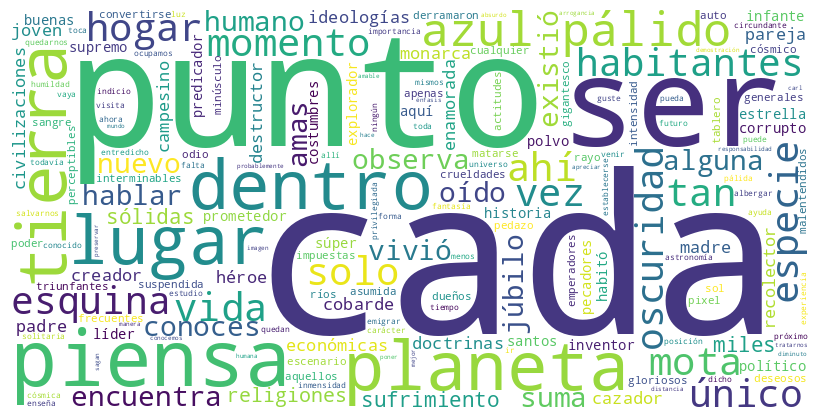

In [96]:
#Creaciòn de la imagen
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()


#Fuente: código ejemplo de esta actividad

# EJERCICIO 2



#### Limpia y preprocesa el texto, descomponelo en oraciones, arma una matriz documento-vocabulario.


In [97]:
#Copia del texto para trabajar el nuevo ejercicio. Y se lo pasa a minúscula
nuevo_texto = texto_completo.lower()
#Busca todo caracter que no sea numeros,letras,espacios y/o puntos y los reemplaza con nada. De esta forma los eliminamos
texto_final = re.sub(r'[^\w\s.]', '', nuevo_texto)
#Se imprime el texto para verlo
print(texto_final)

#Fuente: Notebook clase 1 sobre limpieza de textos

el punto azul pálido
observa de nuevo ese punto. ahí es donde estamos. ese es nuestro hogar. esos somos nosotros. sobre ese punto se encuentra cada ser que amas cada ser que conoces cada ser del que has oído hablar cada ser humano que alguna vez existió y vivió su vida. ahí está la suma de nuestro júbilo y nuestro sufrimiento de miles de sólidas religiones ideologías y doctrinas económicas de cada cazador y recolector de cada héroe y cada cobarde de cada creador y destructor de civilizaciones de cada monarca y campesino de cada joven pareja enamorada cada madre padre y prometedor infante de cada inventor y explorador de cada predicador de buenas costumbres y cada político corrupto de cada súper estrella y líder supremo. cada uno de los santos y pecadores en la historia de nuestra especie habitó aquí en una mota de polvo suspendida en un rayo de sol.
el planeta tierra es un minúsculo tablero dentro de un gigantesco escenario cósmico. piensa en los ríos de sangre que derramaron todos aqu

In [98]:
#Separa en oraciones en base a puntos o saltos de línea.
oraciones = re.split(r'\.|\n', texto_final)
#Se imprimen las oraciones resultantes en una lista
print(oraciones)

#Fuente: se le pidió a ChatGPT: "como adapto el argumento de .splt para que separe en oraciones segùn si hay un punto o un salto de lìnea"

['el punto azul pálido', 'observa de nuevo ese punto', ' ahí es donde estamos', ' ese es nuestro hogar', ' esos somos nosotros', ' sobre ese punto se encuentra cada ser que amas cada ser que conoces cada ser del que has oído hablar cada ser humano que alguna vez existió y vivió su vida', ' ahí está la suma de nuestro júbilo y nuestro sufrimiento de miles de sólidas religiones ideologías y doctrinas económicas de cada cazador y recolector de cada héroe y cada cobarde de cada creador y destructor de civilizaciones de cada monarca y campesino de cada joven pareja enamorada cada madre padre y prometedor infante de cada inventor y explorador de cada predicador de buenas costumbres y cada político corrupto de cada súper estrella y líder supremo', ' cada uno de los santos y pecadores en la historia de nuestra especie habitó aquí en una mota de polvo suspendida en un rayo de sol', '', 'el planeta tierra es un minúsculo tablero dentro de un gigantesco escenario cósmico', ' piensa en los ríos de

In [99]:
#Convierte cada oración en una lista de palabras
documentos = np.char.split(oraciones)
print(documentos)

#Fuente: notebook clase 1 sobre vectorización

[list(['el', 'punto', 'azul', 'pálido'])
 list(['observa', 'de', 'nuevo', 'ese', 'punto'])
 list(['ahí', 'es', 'donde', 'estamos'])
 list(['ese', 'es', 'nuestro', 'hogar'])
 list(['esos', 'somos', 'nosotros'])
 list(['sobre', 'ese', 'punto', 'se', 'encuentra', 'cada', 'ser', 'que', 'amas', 'cada', 'ser', 'que', 'conoces', 'cada', 'ser', 'del', 'que', 'has', 'oído', 'hablar', 'cada', 'ser', 'humano', 'que', 'alguna', 'vez', 'existió', 'y', 'vivió', 'su', 'vida'])
 list(['ahí', 'está', 'la', 'suma', 'de', 'nuestro', 'júbilo', 'y', 'nuestro', 'sufrimiento', 'de', 'miles', 'de', 'sólidas', 'religiones', 'ideologías', 'y', 'doctrinas', 'económicas', 'de', 'cada', 'cazador', 'y', 'recolector', 'de', 'cada', 'héroe', 'y', 'cada', 'cobarde', 'de', 'cada', 'creador', 'y', 'destructor', 'de', 'civilizaciones', 'de', 'cada', 'monarca', 'y', 'campesino', 'de', 'cada', 'joven', 'pareja', 'enamorada', 'cada', 'madre', 'padre', 'y', 'prometedor', 'infante', 'de', 'cada', 'inventor', 'y', 'explorador'

In [100]:
#Construye una lista de palabras (vocabulario) únicas en base a los documentos anteriormente obtenidos
tokens = []

for doc in documentos:
  for word in doc:
    if np.isin(word,tokens) == False:
      tokens = np.append(tokens,word)
      #print(word)

print(tokens)


#Fuente: notebook clase 1 sobre vectorización

['el' 'punto' 'azul' 'pálido' 'observa' 'de' 'nuevo' 'ese' 'ahí' 'es'
 'donde' 'estamos' 'nuestro' 'hogar' 'esos' 'somos' 'nosotros' 'sobre'
 'se' 'encuentra' 'cada' 'ser' 'que' 'amas' 'conoces' 'del' 'has' 'oído'
 'hablar' 'humano' 'alguna' 'vez' 'existió' 'y' 'vivió' 'su' 'vida' 'está'
 'la' 'suma' 'júbilo' 'sufrimiento' 'miles' 'sólidas' 'religiones'
 'ideologías' 'doctrinas' 'económicas' 'cazador' 'recolector' 'héroe'
 'cobarde' 'creador' 'destructor' 'civilizaciones' 'monarca' 'campesino'
 'joven' 'pareja' 'enamorada' 'madre' 'padre' 'prometedor' 'infante'
 'inventor' 'explorador' 'predicador' 'buenas' 'costumbres' 'político'
 'corrupto' 'súper' 'estrella' 'líder' 'supremo' 'uno' 'los' 'santos'
 'pecadores' 'en' 'historia' 'nuestra' 'especie' 'habitó' 'aquí' 'una'
 'mota' 'polvo' 'suspendida' 'un' 'rayo' 'sol' 'planeta' 'tierra'
 'minúsculo' 'tablero' 'dentro' 'gigantesco' 'escenario' 'cósmico'
 'piensa' 'ríos' 'sangre' 'derramaron' 'todos' 'aquellos' 'generales'
 'emperadores' 'p


#### 2.3.2 Determina la longitud de tu vocabulario.

In [101]:
len_tokens = len(tokens)
print(len_tokens)


#Fuente: conocimiento propio del uso del "len" (aprendido durante la carrera)

240



#### 2.3.3. Aplica TF-IDF a tu matriz documento-vocabulario

In [102]:
def frecuency_matrix(documento_list, tokens_list,len_tokens):
  n_doc = documento_list.size
  frecuencias = np.zeros((n_doc,len_tokens),dtype = np.uint8)

  fila = 0
  for doc in documento_list:
    #print(doc)
    for word in doc:
      #print(word)
      if word in tokens_list:
        i = tokens_list.tolist().index(word)
        #print(i)
        frecuencias[fila,i]= frecuencias[fila,i]+1

    fila = fila + 1

  return frecuencias

print(frecuency_matrix(documentos, tokens,len_tokens))


#Fuente: notebook clase 1 sobre vectorización

[[1 1 1 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [2 1 1 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [1 1 1 ... 1 1 1]]


In [103]:

# calcular IDF
# Se obtiene como la división de la cantidad de documentos sobre la
# suma en axis=0 (vertical) del OneHotEncoding.
def inverse_document_frequency(documento_list, tokens_list,len_tokens):

  n_doc = documento_list.size

  Freq = frecuency_matrix(documento_list, tokens_list,len_tokens)

  div = (n_doc * 1.0) / (np.sum(Freq,axis=0) * 1.0)

  #print(div)

  return np.log10(div)

IDF = inverse_document_frequency(documentos, tokens,len_tokens)

print(IDF )
# calcular TF
TF = frecuency_matrix(documentos, tokens,len_tokens)
print(TF)
# regresar TF-IDF

def TF_IDF_function(documento_list, tokens_list, len_tokens):
  return frecuency_matrix(documentos,tokens,len_tokens) * inverse_document_frequency(documentos, tokens,len_tokens)


TF_IDF_function(documentos,tokens,len_tokens)
#Fuente: notebook clase 1 sobre vectorización

[ 0.49291552  0.60205999  0.97003678  0.97003678  1.44715803 -0.17609126
  1.44715803  0.84509804  1.14612804  0.54406804  1.14612804  1.44715803
  0.74818803  1.14612804  1.44715803  1.44715803  1.14612804  1.14612804
  1.14612804  1.44715803  0.24303805  0.84509804  0.27106677  1.44715803
  1.44715803  1.14612804  1.44715803  1.44715803  1.44715803  1.44715803
  1.44715803  1.14612804  1.44715803  0.24303805  1.44715803  1.14612804
  1.14612804  1.44715803  0.40576535  1.44715803  1.44715803  1.44715803
  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803
  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803
  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803
  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803
  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803  1.44715803
  1.44715803  1.44715803  1.44715803  1.44715803  0.66900678  1.44715803
  1.44715803  0.27106677  1.44715803  0.74818803  1

array([[0.49291552, 0.60205999, 0.97003678, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.60205999, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.98583104, 0.60205999, 0.97003678, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.49291552, 0.60205999, 0.97003678, ..., 1.44715803, 1.44715803,
        1.44715803]])

Explica el formato de tu matriz resultante: documentos, vocabulario, tamaño. Brinda tus conclusiones.

La matriz resultante tiene en sus filas los documentos (oraciones) y en sus columnas, los elementos del vocabulario(Palabras). El tamaño entonces es la cantidad de documentos por la cantidad de elementos del vocabulario. Los valores de la matriz, por otro lado, representan el peso o la relevancia de cada palabra en cada oración.

Por relevancia, me refiero a que tan característica es esa palabra en una oración en relación con el resto de documentos. Si el valor es 0, la palabra no aparece en el documento. Si la palabra es frecuente en la oración, y a su vez, aparece en muy pocas oraciones, ayuda a caracterizarlas mejor, y por lo tanto, tendrá un valor TF-IDF alto.



# Conclusiones

Es mi primer acercamiento al procesamiento de palabras. Me pareció muy interesante la relación entre la gramàtica y las formas de representarlas mediante números u otras essructuras para poder calcular relevancias. A su vez, es esto lo que me representó un mayor desafío: justamente entender como una palabra podría "calcularse" y las nuevas librerías con todas sus posibilidades.
Como autocrítica o potencial mejora, probaría calcular la matriz final pero sobre un vocabulario sin las stopwords. Quizas en un proyecto mas complejo para ver el beneficio/costo en el entrenamiento de un modelo. En este caso, decidí conservarlas, ya que varias de mis oraciones se reducían a stopwords, generando documentos vacíos. Pero soy consciente que estas palabras pueden generar ruido.



# Anexo, código de ejemplo del uso de wordcloud

Instalar e importar la librería

In [104]:
# instalar wordcloud
!pip install wordcloud


In [105]:

# Importar librerías
from wordcloud import WordCloud
import matplotlib.pyplot as plt


In [106]:

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Crear un objeto WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)


Mostramos la imagen generada

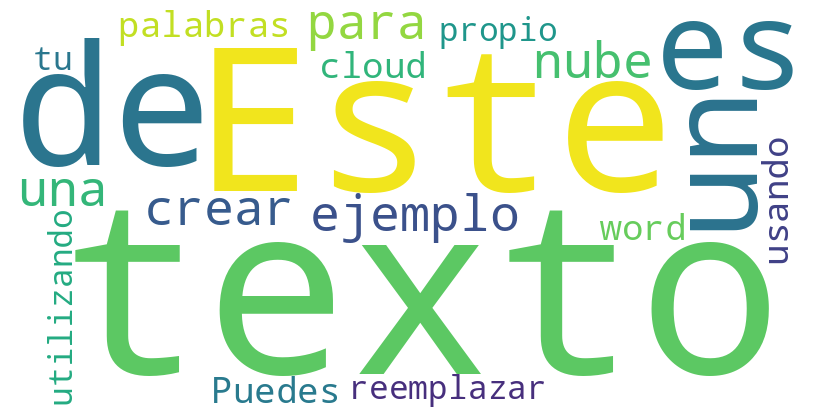

In [107]:

# mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()

Modificamos el ejemplo anterior agregando palabras en español que no queremos que considere para crear la nube de palabras. Estas son las stop_words



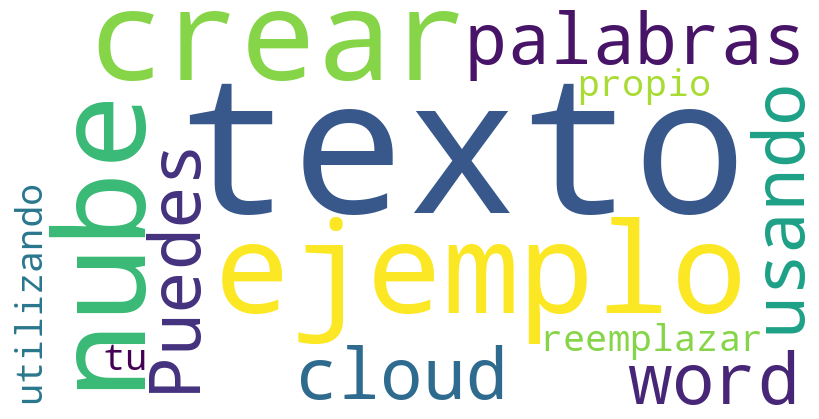

In [108]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Texto de ejemplo
text = "Este es un texto de ejemplo para crear una nube de palabras usando word cloud. Puedes reemplazar este texto utilizando tu propio texto."

# Definir stopwords en español
stopwords_es = set(STOPWORDS)
stopwords_es.update(["con", "que", "los", "para", "un", "una", "el", "la", "en", "y", "o", "de", "a", "se", "es", "al", "como", "por", "no", "su", "más", "pero", "si", "este", "esta", "eso", "esa", "todo", "todos", "todas", "cada", "cual", "cualquier", "algo", "alguna", "algún", "ningún", "ninguna", "ninguno", "otro", "otros", "otras", "sobre", "entre", "durante", "desde", "hasta", "también", "así", "mismo", "misma", "mismo", "misma", "tan", "tanto", "tanta", "muy", "poco", "poca", "poco", "nada", "solo", "sola", "solo", "sola", "siempre", "nunca", "jamás", "casi", "aproximadamente", "cerca", "lejos", "antes", "después", "ahora", "hoy", "ayer", "mañana", "luego", "mientras", "mientras tanto", "después de", "antes de", "durante", "sin", "aunque", "a pesar de", "debido a", "gracias a", "por qué", "cómo", "dónde", "cuándo", "quién", "qué", "cuál"])

# Crear un objeto WordCloud con stopwords en español
wordcloud = WordCloud(width=800, height=400, background_color="white", stopwords=stopwords_es).generate(text)

# Mostramos la imagen generada
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.show()
